# 01 — Data acquisition and research design

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import html
import json
import platform
import re
import sys
import time
import unicodedata
import xml.etree.ElementTree as ET

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display

mpl.rcParams.update(
    {
        "font.family": "Times New Roman",
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 19,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.titlesize": 20,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.unicode_minus": True,
        "savefig.dpi": 350,
        "figure.dpi": 350,
    }
)
PALETTE = {
    "blue": "#2F6B8F",
    "orange": "#C77C2B",
    "green": "#4F7F3A",
    "purple": "#6D5A8D",
    "red": "#B45A55",
    "gray": "#6E7378",
    "light_gray": "#E7EAED",
    "teal": "#4A8C8A",
    "gold": "#C9A227",
    "black": "#222222",
    "white": "#FFFFFF",
}

In [2]:
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
assert (PROJECT_ROOT / "Tasks_for_Codex.md").exists(), PROJECT_ROOT

DIRS = {
    "openalex_raw": PROJECT_ROOT / "dataset/raw/openalex",
    "arxiv_raw": PROJECT_ROOT / "dataset/raw/arxiv",
    "s2_raw": PROJECT_ROOT / "dataset/raw/semantic_scholar",
    "processed": PROJECT_ROOT / "dataset/processed",
    "unified": PROJECT_ROOT / "dataset/unified",
    "external": PROJECT_ROOT / "dataset/external_test",
    "tables": PROJECT_ROOT / "results/tables",
    "reports": PROJECT_ROOT / "results/reports",
    "figures": PROJECT_ROOT / "results/figures",
    "models": PROJECT_ROOT / "results/models",
}
for path in DIRS.values():
    path.mkdir(parents=True, exist_ok=True)

structure = pd.DataFrame(
    [
        {
            "artifact_area": name,
            "path": str(path.relative_to(PROJECT_ROOT)),
            "exists": path.exists(),
        }
        for name, path in DIRS.items()
    ]
)
display(structure)
assert structure["exists"].all()

,artifact_area,path,exists
0,openalex_raw,dataset/raw/openalex,True
1,arxiv_raw,dataset/raw/arxiv,True
2,s2_raw,dataset/raw/semantic_scholar,True
3,processed,dataset/processed,True
4,unified,dataset/unified,True
5,external,dataset/external_test,True
6,tables,results/tables,True
7,reports,results/reports,True
8,figures,results/figures,True
9,models,results/models,True


## Pre-declared corpus design

The main corpus is a deterministic multi-seed OpenAlex sample from eight broad fields. The window 2018–2024 avoids mixing the later arXiv source/time shift into model development. arXiv categories are mapped into the same declared label space and are reserved for external-like evaluation. A taxonomy field used to derive the label is evidence, not a predictive feature.

In [3]:
RANDOM_SEED = 20260716
OPENALEX_START_DATE = "2018-01-01"
OPENALEX_END_DATE = "2024-12-31"
OPENALEX_PER_CLASS = 1250
OPENALEX_BATCH_SIZE = 200
OPENALEX_SEEDS = [RANDOM_SEED + i * 7919 for i in range(8)]
ARXIV_PER_CLASS = 150

CLASS_DESIGN = [
    ("Computer Science", 17, "cat:cs.*"),
    ("Mathematics", 26, "cat:math.*"),
    ("Physics and Astronomy", 31, "cat:astro-ph.*"),
    ("Engineering", 22, "cat:eess.*"),
    ("Materials Science", 25, "cat:cond-mat.mtrl-sci"),
    ("Economics, Econometrics and Finance", 20, "cat:q-fin.*"),
    ("Biochemistry, Genetics and Molecular Biology", 13, "cat:q-bio.*"),
    ("Medicine", 27, "cat:physics.med-ph"),
]
class_design_df = pd.DataFrame(
    CLASS_DESIGN, columns=["thematic_class", "openalex_field_id", "arxiv_query"]
)
class_design_df["openalex_target"] = OPENALEX_PER_CLASS
class_design_df["arxiv_external_target"] = ARXIV_PER_CLASS
display(class_design_df)

request_config = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "random_seed": RANDOM_SEED,
    "openalex": {
        "endpoint": "https://api.openalex.org/works",
        "date_range": [OPENALEX_START_DATE, OPENALEX_END_DATE],
        "per_class": OPENALEX_PER_CLASS,
        "batch_size": OPENALEX_BATCH_SIZE,
        "sample_seeds": OPENALEX_SEEDS,
        "filters": ["primary_topic.field.id", "has_abstract:true", "language:en"],
    },
    "arxiv": {
        "endpoint": "https://export.arxiv.org/api/query",
        "per_class": ARXIV_PER_CLASS,
        "sort": "submittedDate descending",
        "role": "disclosed_source_shift_validation",
    },
    "semantic_scholar": {
        "endpoint": "https://api.semanticscholar.org/graph/v1/paper/batch",
        "role": "metadata_enrichment_attempt_only",
    },
    "classes": class_design_df.to_dict(orient="records"),
}
config_path = DIRS["openalex_raw"] / "request_config.json"
config_path.write_text(json.dumps(request_config, indent=2, ensure_ascii=False), encoding="utf-8")
display(
    pd.DataFrame([{"parameter": k, "value": str(v)} for k, v in request_config["openalex"].items()])
)

,thematic_class,openalex_field_id,arxiv_query,openalex_target,arxiv_external_target
0,Computer Science,17,cat:cs.*,1250,150
1,Mathematics,26,cat:math.*,1250,150
2,Physics and Astronomy,31,cat:astro-ph.*,1250,150
3,Engineering,22,cat:eess.*,1250,150
4,Materials Science,25,cat:cond-mat.mtrl-sci,1250,150
5,"Economics, Econometrics and Finance",20,cat:q-fin.*,1250,150
6,"Biochemistry, Genetics and Molecular Biology",13,cat:q-bio.*,1250,150
7,Medicine,27,cat:physics.med-ph,1250,150


,parameter,value
0,endpoint,https://api.openalex.org/works
1,date_range,"['2018-01-01', '2024-12-31']"
2,per_class,1250
3,batch_size,200
4,sample_seeds,"[20260716, 20268635, 20276554, 20284473, 20292..."
5,filters,"['primary_topic.field.id', 'has_abstract:true'..."


## OpenAlex download

Each HTTP response is written unchanged before parsing. Multiple fixed sample seeds are used because the OpenAlex sample endpoint returns at most one page. Existing valid raw files are reused, making the cell resumable without silently replacing source evidence.

In [4]:
session = requests.Session()
session.headers.update(
    {
        "User-Agent": "MASSK-reproducible-research/1.0 (notebook-only academic project)",
        "Accept": "application/json",
    }
)
download_rows = []

for class_name, field_id, _ in CLASS_DESIGN:
    slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    for seed in OPENALEX_SEEDS:
        raw_path = DIRS["openalex_raw"] / f"{slug}__seed_{seed}.json"
        params = {
            "filter": (
                f"primary_topic.field.id:{field_id},has_abstract:true,language:en,"
                f"from_publication_date:{OPENALEX_START_DATE},"
                f"to_publication_date:{OPENALEX_END_DATE}"
            ),
            "sample": OPENALEX_BATCH_SIZE,
            "seed": seed,
            "per-page": OPENALEX_BATCH_SIZE,
        }
        status = "reused"
        http_status = 200
        if not raw_path.exists():
            for attempt in range(5):
                response = session.get("https://api.openalex.org/works", params=params, timeout=90)
                http_status = response.status_code
                if response.ok:
                    raw_path.write_bytes(response.content)
                    status = "downloaded"
                    break
                time.sleep(min(2**attempt, 20))
            else:
                raise RuntimeError(
                    f"OpenAlex failed for {class_name}, seed={seed}: HTTP {http_status}"
                )
            time.sleep(0.15)
        payload = json.loads(raw_path.read_text(encoding="utf-8"))
        download_rows.append(
            {
                "source": "OpenAlex",
                "request_group": class_name,
                "raw_file": str(raw_path.relative_to(PROJECT_ROOT)),
                "status": status,
                "http_status": http_status,
                "requested_records": OPENALEX_BATCH_SIZE,
                "response_records": len(payload.get("results", [])),
                "request_timestamp_utc": datetime.fromtimestamp(
                    raw_path.stat().st_mtime, tz=timezone.utc
                ).isoformat(),
                "parameters_json": json.dumps(params, sort_keys=True),
                "sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest(),
            }
        )

openalex_download_df = pd.DataFrame(download_rows)
display(
    openalex_download_df.groupby(["source", "status"], as_index=False).agg(
        files=("raw_file", "count"), response_records=("response_records", "sum")
    )
)
assert openalex_download_df["http_status"].eq(200).all()
assert openalex_download_df["response_records"].gt(0).all()

,source,status,files,response_records
0,OpenAlex,reused,64,12800


## Parse OpenAlex into a structured source table

In [5]:
def reconstruct_abstract(inverted_index):
    if not inverted_index:
        return ""
    positions = [(position, token) for token, locs in inverted_index.items() for position in locs]
    return " ".join(token for position, token in sorted(positions))


openalex_rows = []
for class_name, field_id, _ in CLASS_DESIGN:
    slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    seen_ids = set()
    class_rows = []
    for seed in OPENALEX_SEEDS:
        raw_path = DIRS["openalex_raw"] / f"{slug}__seed_{seed}.json"
        for work in json.loads(raw_path.read_text(encoding="utf-8")).get("results", []):
            work_id = work.get("id", "")
            if not work_id or work_id in seen_ids:
                continue
            primary_topic = work.get("primary_topic") or {}
            primary_field = (primary_topic.get("field") or {}).get("display_name", "")
            if primary_field != class_name:
                continue
            seen_ids.add(work_id)
            authorships = work.get("authorships") or []
            primary_location = work.get("primary_location") or {}
            source_meta = primary_location.get("source") or {}
            topics = work.get("topics") or []
            keywords = work.get("keywords") or []
            ids = work.get("ids") or {}
            class_rows.append(
                {
                    "sample_id": f"openalex:{work_id.rsplit('/', 1)[-1]}",
                    "source": "openalex",
                    "paper_id": work_id,
                    "doi": ids.get("doi") or work.get("doi") or "",
                    "title": work.get("title") or work.get("display_name") or "",
                    "abstract": reconstruct_abstract(work.get("abstract_inverted_index")),
                    "publication_year": work.get("publication_year"),
                    "publication_date": work.get("publication_date") or "",
                    "language": work.get("language") or "",
                    "source_name": source_meta.get("display_name") or "",
                    "source_type": source_meta.get("type") or "",
                    "authors_json": json.dumps(
                        [(a.get("author") or {}).get("display_name", "") for a in authorships],
                        ensure_ascii=False,
                    ),
                    "institutions_json": json.dumps(
                        sorted(
                            {
                                i.get("display_name", "")
                                for a in authorships
                                for i in (a.get("institutions") or [])
                                if i.get("display_name")
                            }
                        ),
                        ensure_ascii=False,
                    ),
                    "cited_by_count": work.get("cited_by_count", 0),
                    "open_access": bool((work.get("open_access") or {}).get("is_oa", False)),
                    "open_access_status": (work.get("open_access") or {}).get("oa_status") or "",
                    "topics_json": json.dumps(
                        [t.get("display_name", "") for t in topics if t.get("display_name")],
                        ensure_ascii=False,
                    ),
                    "subfields_json": json.dumps(
                        sorted(
                            {
                                (t.get("subfield") or {}).get("display_name", "")
                                for t in topics
                                if (t.get("subfield") or {}).get("display_name")
                            }
                        ),
                        ensure_ascii=False,
                    ),
                    "fields_json": json.dumps(
                        sorted(
                            {
                                (t.get("field") or {}).get("display_name", "")
                                for t in topics
                                if (t.get("field") or {}).get("display_name")
                            }
                        ),
                        ensure_ascii=False,
                    ),
                    "keywords_json": json.dumps(
                        [k.get("display_name", "") for k in keywords if k.get("display_name")],
                        ensure_ascii=False,
                    ),
                    "work_type": work.get("type") or "",
                    "identifiers_json": json.dumps(ids, ensure_ascii=False, sort_keys=True),
                    "thematic_class": class_name,
                    "target_provenance": "OpenAlex primary_topic.field",
                    "split_role": "development_pool",
                }
            )
            if len(class_rows) >= OPENALEX_PER_CLASS:
                break
        if len(class_rows) >= OPENALEX_PER_CLASS:
            break
    openalex_rows.extend(class_rows)

openalex_df = pd.DataFrame(openalex_rows)
openalex_path = DIRS["processed"] / "openalex_records.parquet"
openalex_df.to_parquet(openalex_path, index=False)
preview = openalex_df.head(3).copy()
preview["abstract_preview"] = preview["abstract"].str.slice(0, 180) + "…"
preview_groups = {
    "Identity and text": ["sample_id", "source", "title", "abstract_preview", "language"],
    "Bibliographic metadata": [
        "doi",
        "publication_year",
        "publication_date",
        "source_name",
        "source_type",
        "cited_by_count",
        "open_access_status",
    ],
    "Taxonomy and provenance": [
        "thematic_class",
        "topics_json",
        "keywords_json",
        "target_provenance",
        "split_role",
    ],
}
for group_name, columns in preview_groups.items():
    display(Markdown(f"**{group_name}**"))
    with pd.option_context(
        "display.max_columns", None, "display.max_colwidth", 180, "display.width", 240
    ):
        display(preview[columns])
display(openalex_df.groupby("thematic_class", as_index=False).size())
assert openalex_df["paper_id"].is_unique
assert openalex_df.groupby("thematic_class").size().min() >= 1000

**Identity and text**

,sample_id,source,title,abstract_preview,language
0,openalex:W3145648318,openalex,Pakcoy Plant Sprinklers Based Internet Of Things,"Agriculture is a pillar of the economy a nation, with the system and the implementation of good agricultural, so will go the nation economic.One of the causes of the lack of ag...",en
1,openalex:W2514083242,openalex,Topology Abstraction Service for IP VPNs: Core Network Partitioning for Resource Sharing,VPN service providers (VSP) and IP-VPN customers have traditionally maintained service demarcation boundaries between their routing and signaling entities. This has resulted in...,en
2,openalex:W4399540505,openalex,Research on the Application and Optimization Strategies of Deep Learning in Large Language Models,The development of deep learning technology provides new opportunities for the construction and application of large language models. This paper systematically explores the cur...,en


**Bibliographic metadata**

,doi,publication_year,publication_date,source_name,source_type,cited_by_count,open_access_status
0,https://doi.org/10.26623/transformatika.v18i2.3034,2021,2021-01-25,Jurnal Transformatika,journal,1,diamond
1,https://doi.org/10.4236/ajor.2018.83011,2018,2018-01-01,American Journal of Operations Research,journal,2,diamond
2,https://doi.org/10.53469/jtpes.2024.04(05).12,2024,2024-05-27,Journal of Theory and Practice of Engineering Science,journal,13,hybrid


**Taxonomy and provenance**

,thematic_class,topics_json,keywords_json,target_provenance,split_role
0,Computer Science,"[""IoT-based Control Systems""]","[""Agriculture"", ""Soil moisture sensor"", ""Arable land"", ""Agricultural engineering"", ""Business"", ""Indonesian"", ""Sowing"", ""Environmental science"", ""Agroforestry"", ""Water content"",...",OpenAlex primary_topic.field,development_pool
1,Computer Science,"[""Network Traffic and Congestion Control"", ""Software-Defined Networks and 5G"", ""Mobile Agent-Based Network Management""]","[""Abstraction"", ""Computer science"", ""Partition (number theory)"", ""Network topology"", ""Computer network"", ""Distributed computing"", ""Core (optical fiber)"", ""Routing (electronic d...",OpenAlex primary_topic.field,development_pool
2,Computer Science,"[""Topic Modeling"", ""Natural Language Processing Techniques"", ""Computational and Text Analysis Methods""]","[""Computer science"", ""Deep learning"", ""Artificial intelligence"", ""Language model"", ""Benchmark (surveying)"", ""Adaptation (eye)"", ""Transfer of learning"", ""Natural language proces...",OpenAlex primary_topic.field,development_pool


,thematic_class,size
0,"Biochemistry, Genetics and Molecular Biology",1250
1,Computer Science,1250
2,"Economics, Econometrics and Finance",1250
3,Engineering,1250
4,Materials Science,1250
5,Mathematics,1250
6,Medicine,1250
7,Physics and Astronomy,1250


## Disclosed arXiv pilot batch for source-shift validation

arXiv is deliberately reserved for external evaluation. Responses are saved as unchanged Atom XML. The three-second request interval follows the public API's conservative usage guidance; cached files make re-execution immediate.

In [6]:
arxiv_manifest_rows = []
for class_name, _, query in CLASS_DESIGN:
    slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    raw_path = DIRS["arxiv_raw"] / f"{slug}.xml"
    params = {
        "search_query": query,
        "start": 0,
        "max_results": 250,
        "sortBy": "submittedDate",
        "sortOrder": "descending",
    }
    status = "reused"
    http_status = 200
    if not raw_path.exists():
        for attempt in range(5):
            response = session.get("https://export.arxiv.org/api/query", params=params, timeout=120)
            http_status = response.status_code
            if response.ok and b"<feed" in response.content:
                raw_path.write_bytes(response.content)
                status = "downloaded"
                break
            time.sleep(min(5 * (attempt + 1), 30))
        else:
            raise RuntimeError(f"arXiv failed for {class_name}: HTTP {http_status}")
        time.sleep(3.1)
    root = ET.fromstring(raw_path.read_bytes())
    entry_count = len(root.findall("{http://www.w3.org/2005/Atom}entry"))
    arxiv_manifest_rows.append(
        {
            "source": "arXiv",
            "request_group": class_name,
            "raw_file": str(raw_path.relative_to(PROJECT_ROOT)),
            "status": status,
            "http_status": http_status,
            "requested_records": 250,
            "response_records": entry_count,
            "request_timestamp_utc": datetime.fromtimestamp(
                raw_path.stat().st_mtime, tz=timezone.utc
            ).isoformat(),
            "parameters_json": json.dumps(params, sort_keys=True),
            "sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest(),
        }
    )

arxiv_download_df = pd.DataFrame(arxiv_manifest_rows)
display(arxiv_download_df[["request_group", "status", "response_records", "http_status"]])
assert arxiv_download_df["response_records"].gt(0).all()

,request_group,status,response_records,http_status
0,Computer Science,reused,250,200
1,Mathematics,reused,250,200
2,Physics and Astronomy,reused,250,200
3,Engineering,reused,250,200
4,Materials Science,reused,250,200
5,"Economics, Econometrics and Finance",reused,250,200
6,"Biochemistry, Genetics and Molecular Biology",reused,250,200
7,Medicine,reused,250,200


In [7]:
ATOM = {"a": "http://www.w3.org/2005/Atom", "x": "http://arxiv.org/schemas/atom"}


def atom_text(entry, path, default=""):
    node = entry.find(path, ATOM)
    return " ".join((node.text or "").split()) if node is not None else default


def mapped_arxiv_class(category):
    rules = [
        ("cs.", "Computer Science"),
        ("math.", "Mathematics"),
        ("astro-ph", "Physics and Astronomy"),
        ("eess.", "Engineering"),
        ("cond-mat.mtrl-sci", "Materials Science"),
        ("q-fin.", "Economics, Econometrics and Finance"),
        ("econ.", "Economics, Econometrics and Finance"),
        ("q-bio.", "Biochemistry, Genetics and Molecular Biology"),
        ("physics.med-ph", "Medicine"),
    ]
    return next((label for prefix, label in rules if category.startswith(prefix)), None)


arxiv_rows = []
seen_arxiv_ids = set()
for requested_class, _, _ in CLASS_DESIGN:
    slug = re.sub(r"[^a-z0-9]+", "_", requested_class.lower()).strip("_")
    root = ET.fromstring((DIRS["arxiv_raw"] / f"{slug}.xml").read_bytes())
    accepted = 0
    for entry in root.findall("a:entry", ATOM):
        paper_url = atom_text(entry, "a:id")
        paper_id = paper_url.rsplit("/", 1)[-1].split("v")[0]
        primary_node = entry.find("x:primary_category", ATOM)
        primary_category = primary_node.attrib.get("term", "") if primary_node is not None else ""
        mapped_class = mapped_arxiv_class(primary_category)
        if mapped_class != requested_class or paper_id in seen_arxiv_ids:
            continue
        categories = [node.attrib.get("term", "") for node in entry.findall("a:category", ATOM)]
        authors = [atom_text(node, "a:name") for node in entry.findall("a:author", ATOM)]
        doi = atom_text(entry, "x:doi")
        published = atom_text(entry, "a:published")
        arxiv_rows.append(
            {
                "sample_id": f"arxiv:{paper_id}",
                "source": "arxiv",
                "paper_id": paper_id,
                "doi": doi,
                "title": atom_text(entry, "a:title"),
                "abstract": atom_text(entry, "a:summary"),
                "publication_year": int(published[:4]) if published[:4].isdigit() else np.nan,
                "publication_date": published[:10],
                "updated_date": atom_text(entry, "a:updated")[:10],
                "language": "en",
                "source_name": "arXiv",
                "source_type": "repository",
                "authors_json": json.dumps(authors, ensure_ascii=False),
                "institutions_json": "[]",
                "cited_by_count": np.nan,
                "open_access": True,
                "open_access_status": "green",
                "topics_json": json.dumps(categories, ensure_ascii=False),
                "subfields_json": json.dumps(categories, ensure_ascii=False),
                "fields_json": json.dumps([mapped_class], ensure_ascii=False),
                "keywords_json": json.dumps(categories, ensure_ascii=False),
                "work_type": "preprint",
                "identifiers_json": json.dumps(
                    {"arxiv": paper_id, "url": paper_url}, sort_keys=True
                ),
                "primary_category": primary_category,
                "categories_json": json.dumps(categories, ensure_ascii=False),
                "thematic_class": mapped_class,
                "target_provenance": "declared arXiv primary-category mapping",
                "split_role": "source_shift_validation",
            }
        )
        seen_arxiv_ids.add(paper_id)
        accepted += 1
        if accepted >= ARXIV_PER_CLASS:
            break

arxiv_df = pd.DataFrame(arxiv_rows)
arxiv_path = DIRS["external"] / "arxiv_external_records.parquet"
arxiv_df.to_parquet(arxiv_path, index=False)
display(arxiv_df.groupby("thematic_class", as_index=False).size())
display(arxiv_df[["sample_id", "primary_category", "thematic_class", "publication_year"]].head())
assert arxiv_df["paper_id"].is_unique

,thematic_class,size
0,"Biochemistry, Genetics and Molecular Biology",143
1,Computer Science,150
2,"Economics, Econometrics and Finance",150
3,Engineering,150
4,Materials Science,150
5,Mathematics,150
6,Medicine,150
7,Physics and Astronomy,150


,sample_id,primary_category,thematic_class,publication_year
0,arxiv:2607.14088,cs.CV,Computer Science,2026
1,arxiv:2607.14086,cs.LG,Computer Science,2026
2,arxiv:2607.14081,cs.LG,Computer Science,2026
3,arxiv:2607.14076,cs.CV,Computer Science,2026
4,arxiv:2607.14075,cs.SE,Computer Science,2026


## Semantic Scholar enrichment attempt

A single official batch request is attempted for a stratified DOI sample. It is enrichment only: no record is dropped if the unauthenticated API is unavailable. The exact HTTP outcome and raw response are retained.

In [8]:
s2_path = DIRS["s2_raw"] / "doi_batch_enrichment.json"
doi_candidates = (
    openalex_df.loc[openalex_df["doi"].astype(str).str.len().gt(0), ["doi", "thematic_class"]]
    .groupby("thematic_class", group_keys=False)
    .head(25)
)
doi_ids = [
    f"DOI:{doi.removeprefix('https://doi.org/').removeprefix('http://doi.org/')}"
    for doi in doi_candidates["doi"].tolist()
]
s2_status = "reused"
s2_http_status = 200
s2_note = ""
if not s2_path.exists() and doi_ids:
    fields = "paperId,title,year,citationCount,influentialCitationCount,fieldsOfStudy,venue,authors,externalIds"
    response = session.post(
        "https://api.semanticscholar.org/graph/v1/paper/batch",
        params={"fields": fields},
        json={"ids": doi_ids},
        timeout=120,
    )
    s2_http_status = response.status_code
    if response.ok:
        s2_path.write_bytes(response.content)
        s2_status = "downloaded"
    else:
        s2_status = "unavailable"
        s2_note = response.text[:300].replace("\n", " ")
        limitation_path = DIRS["s2_raw"] / "availability_limitation.json"
        limitation_path.write_text(
            json.dumps(
                {
                    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
                    "http_status": s2_http_status,
                    "message": s2_note,
                    "continuation": "OpenAlex and arXiv retained; Semantic Scholar excluded from modeling.",
                },
                indent=2,
            ),
            encoding="utf-8",
        )

s2_records = []
if s2_path.exists():
    s2_records = json.loads(s2_path.read_text(encoding="utf-8"))
    s2_records = [record for record in s2_records if record]
    s2_status = "reused" if s2_status == "reused" else s2_status
    s2_http_status = 200

s2_manifest_row = {
    "source": "Semantic Scholar",
    "request_group": "stratified DOI enrichment",
    "raw_file": (
        str(s2_path.relative_to(PROJECT_ROOT))
        if s2_path.exists()
        else "dataset/raw/semantic_scholar/availability_limitation.json"
    ),
    "status": s2_status,
    "http_status": s2_http_status,
    "requested_records": len(doi_ids),
    "response_records": len(s2_records),
    "request_timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "parameters_json": json.dumps({"ids": len(doi_ids), "batch": True}, sort_keys=True),
    "sha256": hashlib.sha256(s2_path.read_bytes()).hexdigest() if s2_path.exists() else "",
}
display(pd.DataFrame([s2_manifest_row]))
if s2_note:
    print("Documented limitation:", s2_note)

,source,request_group,raw_file,status,http_status,requested_records,response_records,request_timestamp_utc,parameters_json,sha256
0,Semantic Scholar,stratified DOI enrichment,dataset/raw/semantic_scholar/doi_batch_enrichm...,reused,200,200,151,2026-07-16T20:54:56.312057+00:00,"{""batch"": true, ""ids"": 200}",d8b8aced2d76965797b977fd1ba569e477a8be76784adf...


## Corpus characteristics: coverage, class balance, years, and language

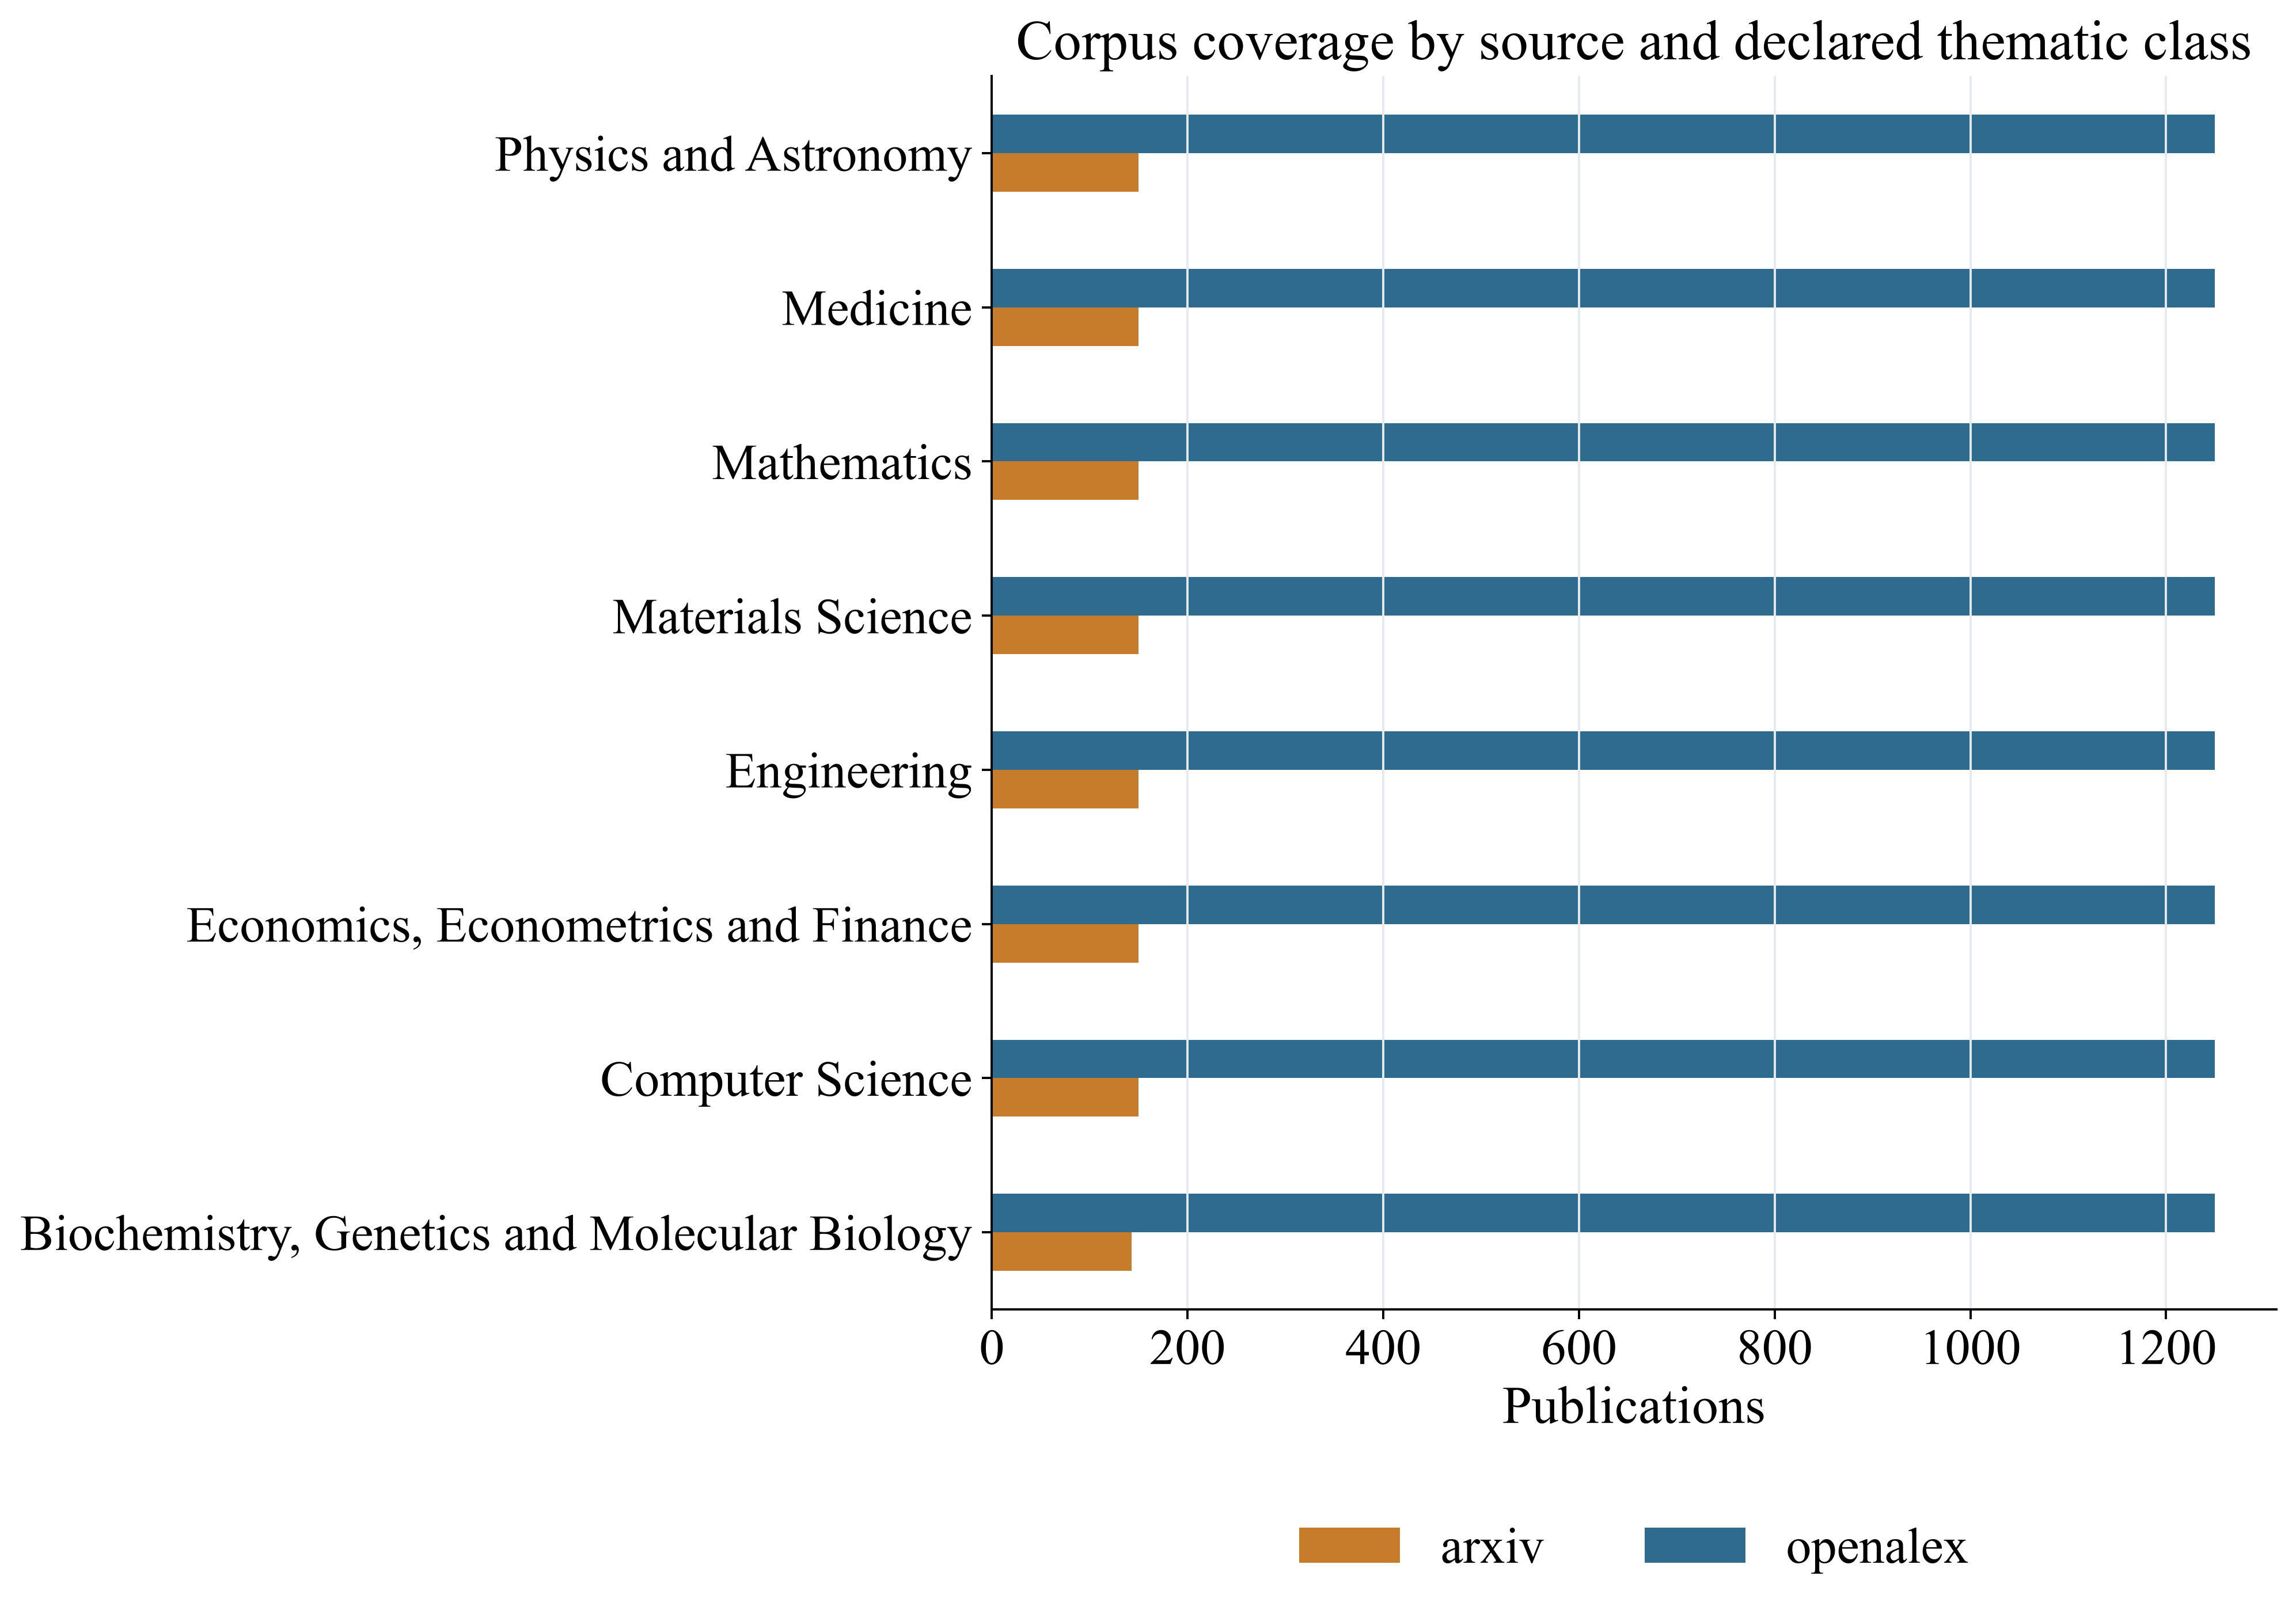

Main class imbalance ratio: 1.0


In [10]:
audit_df = pd.concat(
    [
        openalex_df.assign(corpus_role="development_pool"),
        arxiv_df.assign(corpus_role="external_test_only"),
    ],
    ignore_index=True,
    sort=False,
)

coverage = audit_df.groupby(["source", "corpus_role", "thematic_class"], as_index=False).agg(
    records=("sample_id", "size"),
    years=("publication_year", "nunique"),
    earliest_year=("publication_year", "min"),
    latest_year=("publication_year", "max"),
    abstract_coverage=("abstract", lambda s: s.fillna("").str.strip().ne("").mean()),
    keyword_coverage=("keywords_json", lambda s: s.fillna("[]").ne("[]").mean()),
)

fig, ax = plt.subplots(figsize=(11.8, 9))
pivot = coverage.pivot(index="thematic_class", columns="source", values="records").fillna(0)
pivot.plot(kind="barh", ax=ax, color=[PALETTE["orange"], PALETTE["blue"]])
ax.set_title("Corpus coverage by source and declared thematic class")
ax.set_xlabel("Publications")
ax.set_ylabel("")
ax.grid(axis="x", color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)
fig.subplots_adjust(left=0.36, bottom=0.20)
plt.show()
print(
    "Main class imbalance ratio:",
    round(
        openalex_df.groupby("thematic_class").size().max()
        / openalex_df.groupby("thematic_class").size().min(),
        3,
    ),
)

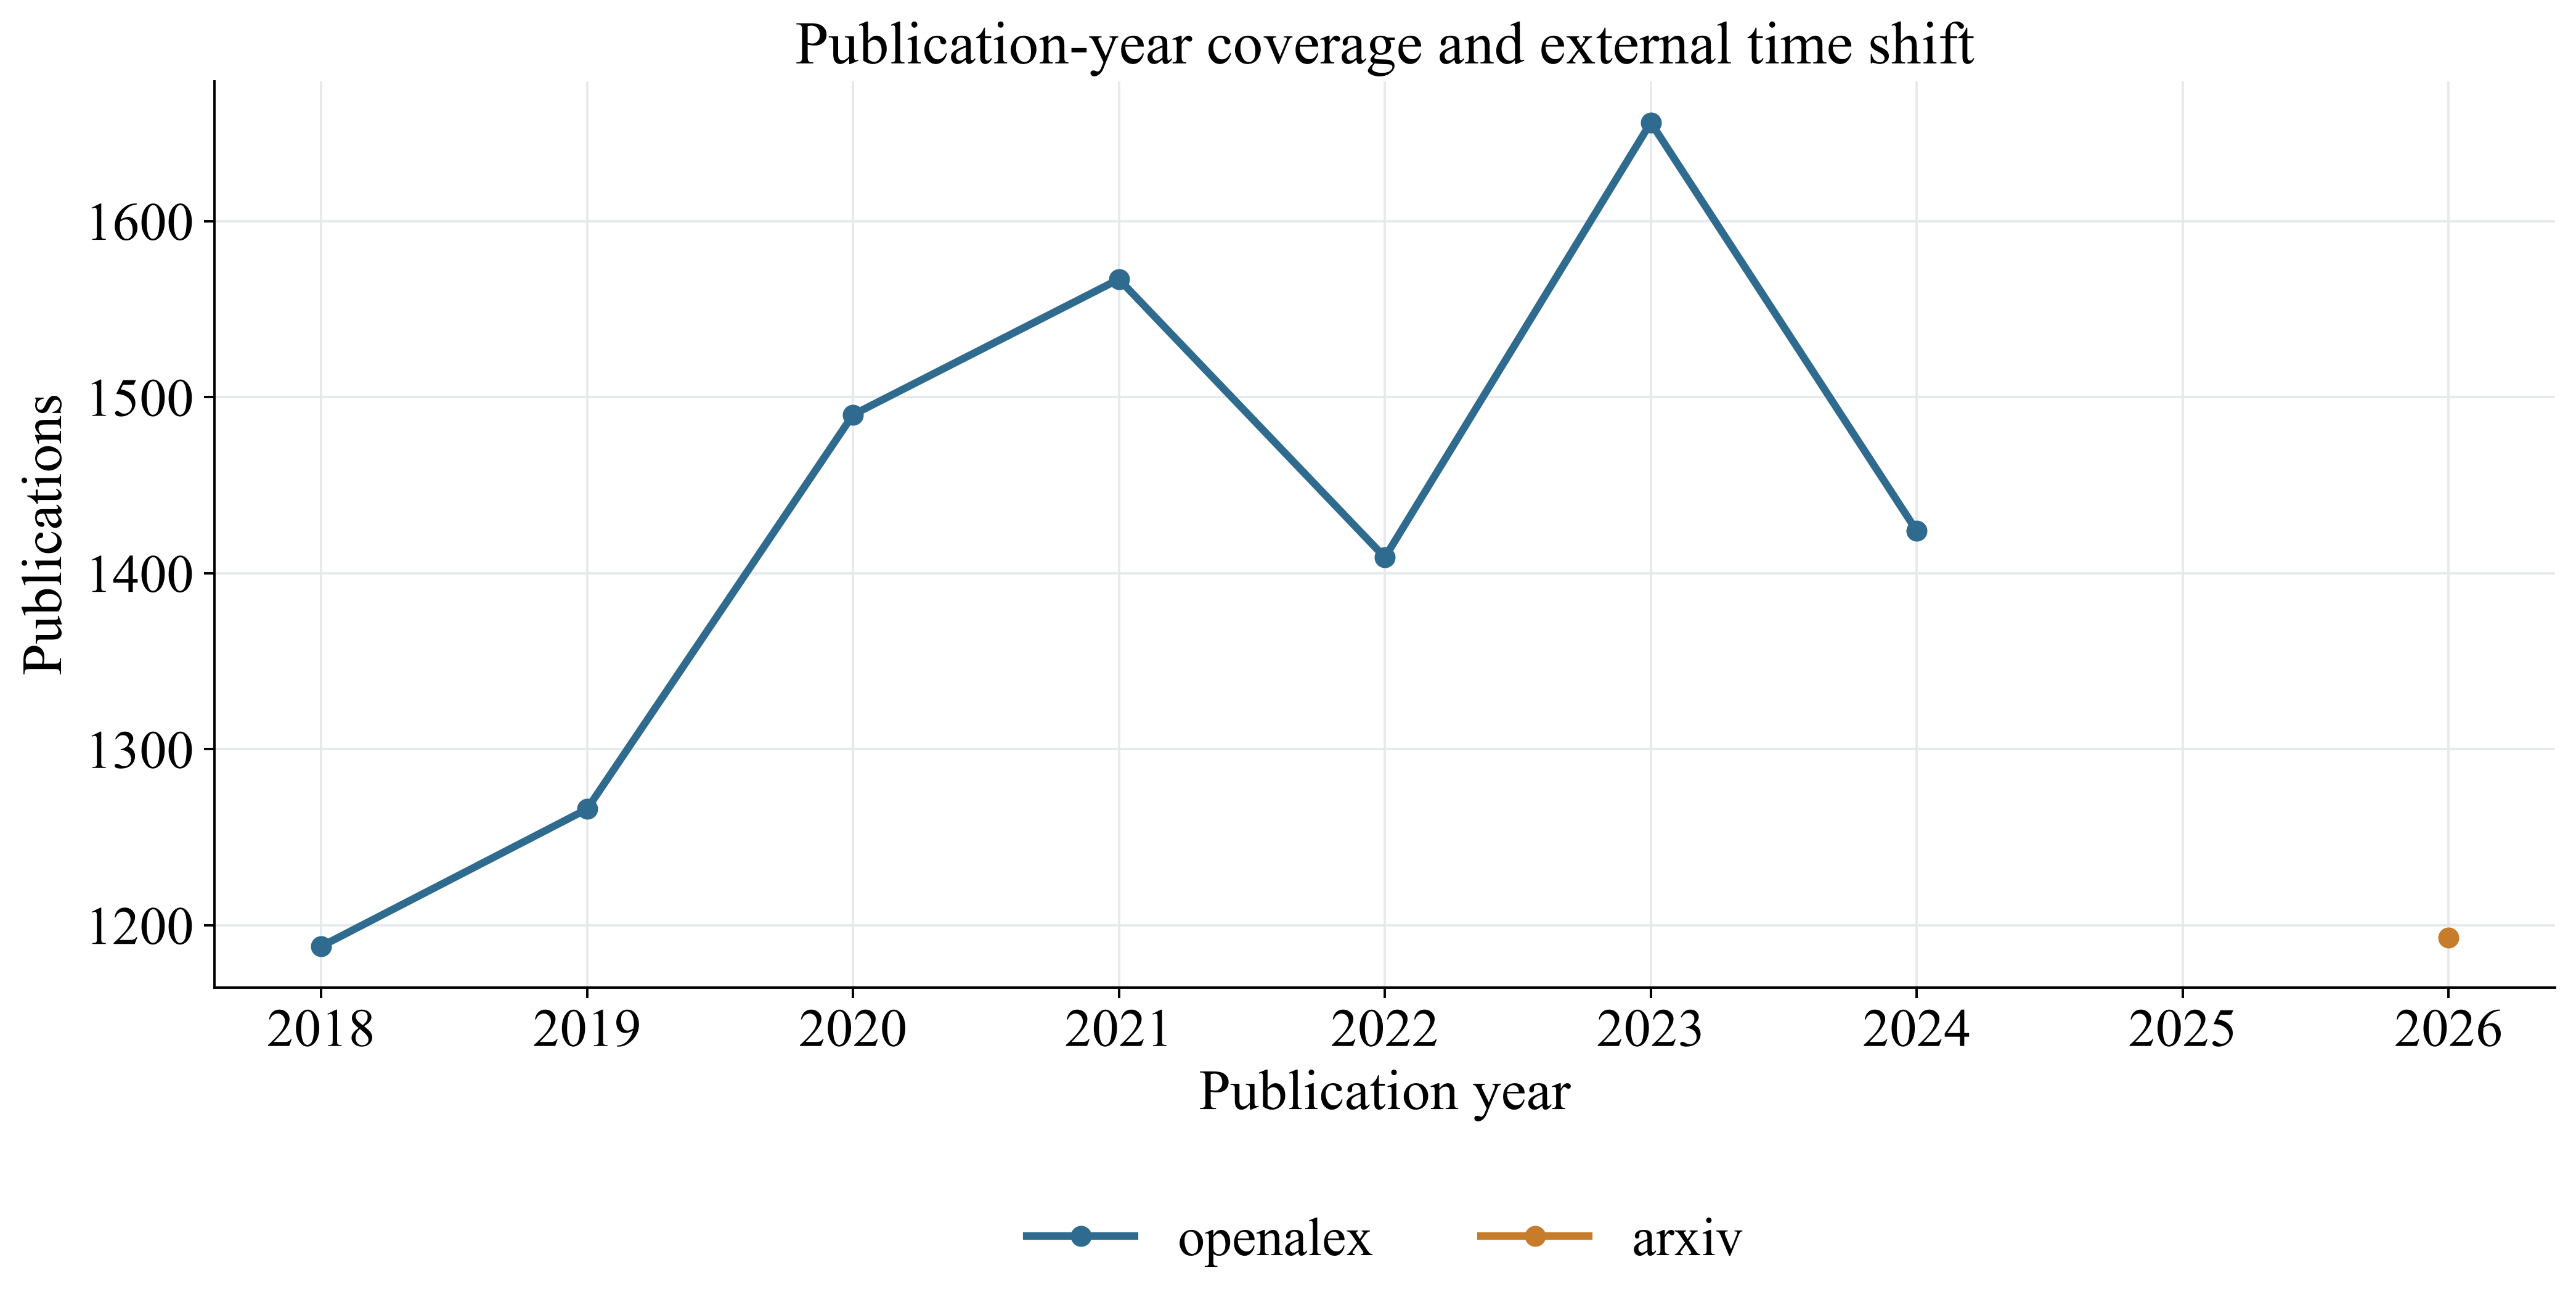

,source,language,size
0,arxiv,en,1193
1,openalex,en,10000


In [11]:
year_source = audit_df.groupby(["publication_year", "source"], as_index=False).size()
fig, ax = plt.subplots(figsize=(14, 7))
for source_name, color in [("openalex", PALETTE["blue"]), ("arxiv", PALETTE["orange"])]:
    part = year_source[year_source["source"].eq(source_name)].sort_values("publication_year")
    ax.plot(
        part["publication_year"],
        part["size"],
        marker="o",
        linewidth=2.5,
        label=source_name,
        color=color,
    )
ax.set_title("Publication-year coverage and external time shift")
ax.set_xlabel("Publication year")
ax.set_ylabel("Publications")
ax.grid(color=PALETTE["light_gray"], linewidth=0.8)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.20), ncol=2, frameon=False)
fig.subplots_adjust(bottom=0.28)
plt.show()

language_summary = audit_df.groupby(["source", "language"], as_index=False).size()
display(language_summary)
assert openalex_df["language"].eq("en").all()
assert arxiv_df["language"].eq("en").all()

## Missingness, availability, and duplicate diagnostics

Duplicates are diagnosed independently by DOI, normalized title, abstract SHA-256 hash, and source identifier. Cross-source duplicates are not silently removed here; Notebook 02 applies the declared priority and verifies that no duplicate group crosses a split.

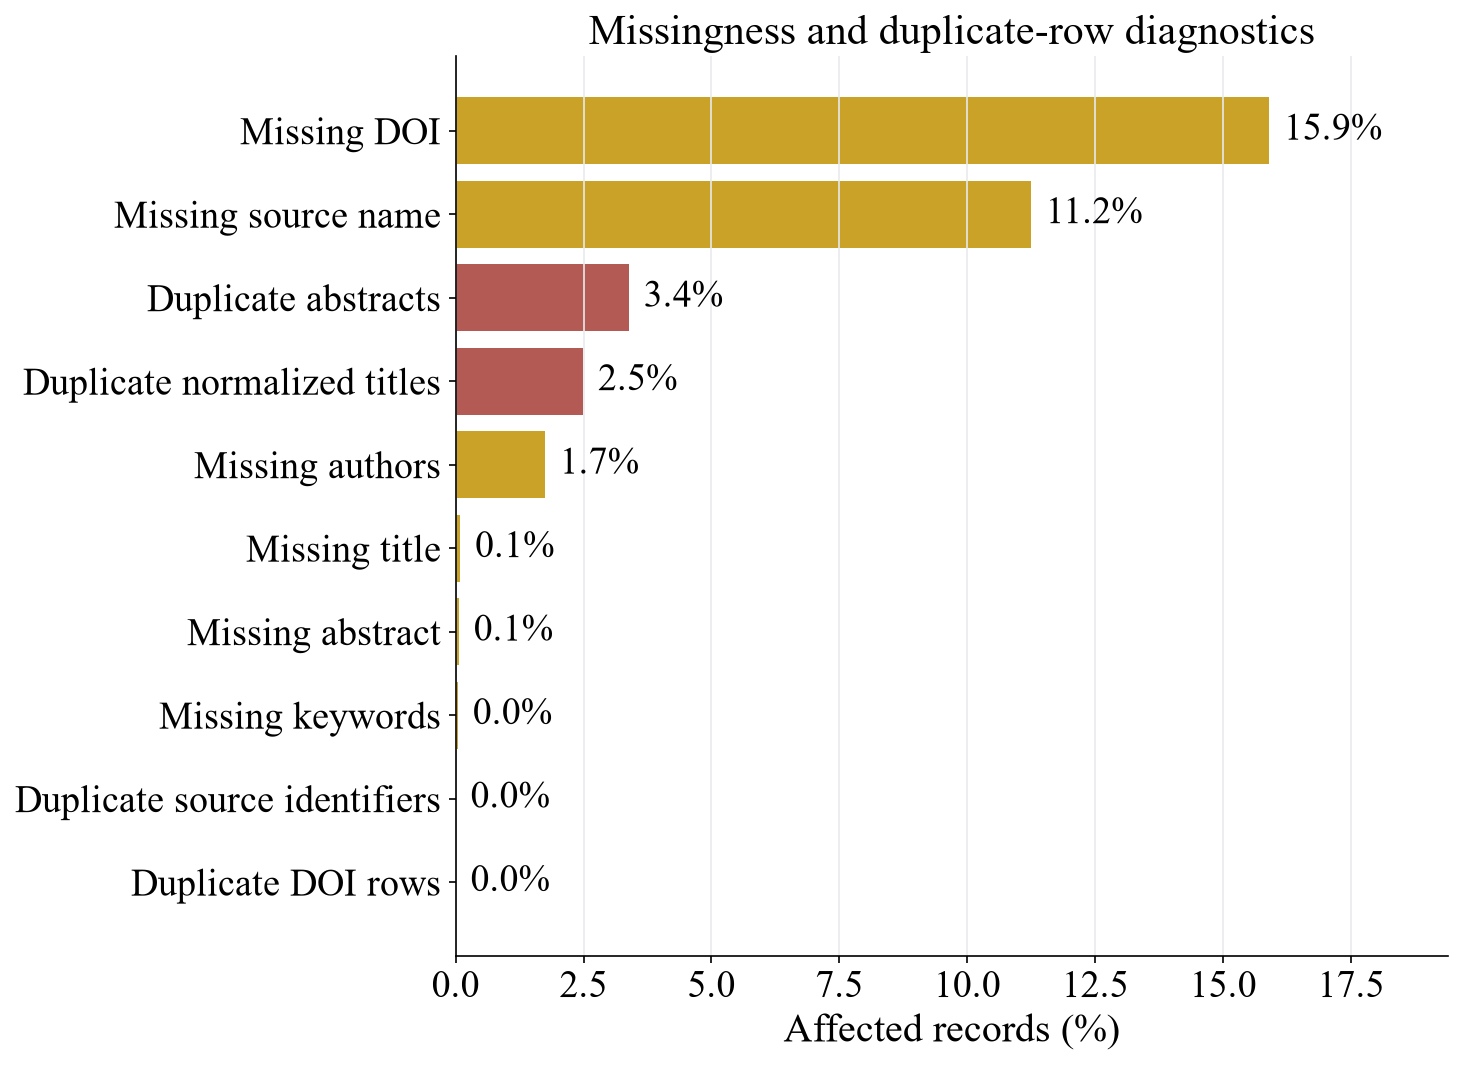

In [12]:
def normalized_title(value):
    value = unicodedata.normalize("NFKC", str(value or "")).casefold()
    return re.sub(r"[^\w]+", " ", value, flags=re.UNICODE).strip()


audit_df["normalized_title_audit"] = audit_df["title"].map(normalized_title)
audit_df["abstract_hash_audit"] = (
    audit_df["abstract"]
    .fillna("")
    .map(
        lambda x: (
            hashlib.sha256(x.strip().casefold().encode("utf-8")).hexdigest() if x.strip() else ""
        )
    )
)
audit_df["normalized_doi_audit"] = (
    audit_df["doi"]
    .fillna("")
    .astype(str)
    .str.casefold()
    .str.replace(r"^https?://(dx\.)?doi\.org/", "", regex=True)
    .str.strip()
)

quality_specs = [
    ("missing_title", audit_df["title"].fillna("").str.strip().eq("")),
    ("missing_abstract", audit_df["abstract"].fillna("").str.strip().eq("")),
    ("missing_doi", audit_df["normalized_doi_audit"].eq("")),
    ("missing_keywords", audit_df["keywords_json"].fillna("[]").eq("[]")),
    ("missing_source_name", audit_df["source_name"].fillna("").str.strip().eq("")),
    ("missing_authors", audit_df["authors_json"].fillna("[]").eq("[]")),
    (
        "duplicate_doi_rows",
        audit_df["normalized_doi_audit"].ne("")
        & audit_df["normalized_doi_audit"].duplicated(keep=False),
    ),
    (
        "duplicate_normalized_title_rows",
        audit_df["normalized_title_audit"].ne("")
        & audit_df["normalized_title_audit"].duplicated(keep=False),
    ),
    (
        "duplicate_abstract_hash_rows",
        audit_df["abstract_hash_audit"].ne("")
        & audit_df["abstract_hash_audit"].duplicated(keep=False),
    ),
    ("duplicate_source_id_rows", audit_df["sample_id"].duplicated(keep=False)),
]
missing_duplicate_df = pd.DataFrame(
    [
        {
            "metric": metric,
            "value": int(mask.sum()),
            "denominator": int(len(audit_df)),
            "rate": float(mask.mean()),
        }
        for metric, mask in quality_specs
    ]
)

diagnostic_labels = {
    'missing_title': 'Missing title',
    'missing_abstract': 'Missing abstract',
    'missing_doi': 'Missing DOI',
    'missing_keywords': 'Missing keywords',
    'missing_source_name': 'Missing source name',
    'missing_authors': 'Missing authors',
    'duplicate_doi_rows': 'Duplicate DOI rows',
    'duplicate_normalized_title_rows': 'Duplicate normalized titles',
    'duplicate_abstract_hash_rows': 'Duplicate abstracts',
    'duplicate_source_id_rows': 'Duplicate source identifiers',
}
plot_df = missing_duplicate_df.sort_values('rate').copy()
plot_df['display_metric'] = plot_df['metric'].map(diagnostic_labels)
fig, ax = plt.subplots(figsize=(10.5, 8))
bars = ax.barh(
    plot_df['display_metric'],
    plot_df['rate'] * 100,
    color=[
        PALETTE['red'] if 'duplicate' in label else PALETTE['gold'] for label in plot_df['metric']
    ],
)
ax.set_title('Missingness and duplicate-row diagnostics')
ax.set_xlabel('Affected records (%)')
ax.set_ylabel('')
ax.grid(axis='x', color=PALETTE['light_gray'], linewidth=0.8)
limit = max(1.0, float((plot_df['rate'] * 100).max()) * 1.22)
ax.set_xlim(0, limit)
for bar, value in zip(bars, plot_df['rate'] * 100):
    ax.text(
        value + limit * 0.015,
        bar.get_y() + bar.get_height() / 2,
        f'{value:.1f}%',
        va='center',
        fontsize=18,
    )
missing_duplicate_df.to_csv(DIRS['tables'] / 'missingness_and_duplicates.csv', index=False)
fig.subplots_adjust(left=0.34, right=0.97, bottom=0.13, top=0.88)
plt.show()

## Evaluation protocol after pilot disclosure

The disclosed random holdout and start-zero arXiv batch are reassigned to development. The OpenAlex and arXiv evaluation cohorts below remained prediction- and metric-blind until Notebook 04 locked the validation-selected configuration. Their class-coverage and label-dependent diagnostics were inspected beforehand; this boundary is retained in the audit rather than hidden.

In [13]:
CONFIRMATORY_SEEDS = [RANDOM_SEED + 400_001, RANDOM_SEED + 800_003]
ARXIV_SOURCE_ID = "S4306400194"
ARXIV_EXTERNAL_SEEDS = [RANDOM_SEED + 1_200_007, RANDOM_SEED + 1_600_009]
prospective_design = pd.DataFrame(
    [
        ("train", "OpenAlex articles", "2018–2022", "model fitting only"),
        (
            "validation",
            "OpenAlex articles + disclosed arXiv pilot",
            "2023–2024 + 2026",
            "model/configuration selection only",
        ),
        ("test", "new OpenAlex articles", "2025", "single post-lock temporal evaluation"),
        (
            "external_test",
            "new OpenAlex-indexed arXiv-hosted works",
            "2024–2025",
            "single post-lock source+metadata+taxonomy stress evaluation",
        ),
    ],
    columns=["split", "source_scope", "time_scope", "allowed_use"],
)
prospective_design["performance_metrics_seen_before_lock"] = False
prospective_design["label_diagnostics_seen_before_lock"] = prospective_design["split"].isin(
    ["test", "external_test"]
)
with pd.option_context(
    "display.max_rows", None, "display.max_colwidth", None, "display.width", 190
):
    display(prospective_design)

,split,source_scope,time_scope,allowed_use,performance_metrics_seen_before_lock,label_diagnostics_seen_before_lock
0,train,OpenAlex articles,2018–2022,model fitting only,False,False
1,validation,OpenAlex articles + disclosed arXiv pilot,2023–2024 + 2026,model/configuration selection only,False,False
2,test,new OpenAlex articles,2025,single post-lock temporal evaluation,False,True
3,external_test,new OpenAlex-indexed arXiv-hosted works,2024–2025,single post-lock source+metadata+taxonomy stress evaluation,False,True


## Download the OpenAlex 2025 evaluation cohort

In [14]:
confirmatory_manifest_rows = []
for class_name, field_id, _ in CLASS_DESIGN:
    class_slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    for seed in CONFIRMATORY_SEEDS:
        raw_path = DIRS["openalex_raw"] / (f"confirmatory_2025__{class_slug}__seed_{seed}.json")
        params = {
            "filter": (
                f"primary_topic.field.id:{field_id},has_abstract:true,language:en,"
                "type:article,from_publication_date:2025-01-01,"
                "to_publication_date:2025-12-31"
            ),
            "sample": 200,
            "seed": seed,
            "per-page": 200,
        }
        status, http_status = "reused", 200
        if not raw_path.exists():
            for attempt in range(5):
                response = session.get("https://api.openalex.org/works", params=params, timeout=90)
                http_status = response.status_code
                if response.ok:
                    raw_path.write_bytes(response.content)
                    status = "downloaded"
                    break
                time.sleep(min(2**attempt, 20))
            else:
                raise RuntimeError(f"OpenAlex confirmatory request failed: {class_name}")
        payload = json.loads(raw_path.read_text(encoding="utf-8"))
        confirmatory_manifest_rows.append(
            {
                "source": "OpenAlex",
                "request_group": class_name,
                "cohort": "confirmatory_test_2025",
                "raw_file": str(raw_path.relative_to(PROJECT_ROOT)),
                "status": status,
                "http_status": http_status,
                "requested_records": 200,
                "response_records": len(payload.get("results", [])),
                "request_timestamp_utc": datetime.fromtimestamp(
                    raw_path.stat().st_mtime, tz=timezone.utc
                ).isoformat(),
                "parameters_json": json.dumps(params, sort_keys=True),
                "sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest(),
                "license_or_terms_url": "https://docs.openalex.org",
            }
        )
confirmatory_download_df = pd.DataFrame(confirmatory_manifest_rows)
display(
    confirmatory_download_df.groupby(["cohort", "status"], as_index=False).agg(
        requests=("raw_file", "count"), records=("response_records", "sum")
    )
)
assert confirmatory_download_df["response_records"].gt(0).all()

,cohort,status,requests,records
0,confirmatory_test_2025,reused,16,3200


## Parse the temporal cohort without model inference

In [15]:
def compact_openalex_record(work, class_name):
    work_id = work.get("id", "")
    location = (work.get("primary_location") or {}).get("source") or {}
    authorships, topics = work.get("authorships") or [], work.get("topics") or []
    identifiers = work.get("ids") or {}
    return {
        "sample_id": f"openalex:{work_id.rsplit('/', 1)[-1]}",
        "source": "openalex",
        "paper_id": work_id,
        "doi": identifiers.get("doi") or work.get("doi") or "",
        "title": work.get("title") or work.get("display_name") or "",
        "abstract": reconstruct_abstract(work.get("abstract_inverted_index")),
        "publication_year": work.get("publication_year"),
        "publication_date": work.get("publication_date") or "",
        "language": work.get("language") or "",
        "source_name": location.get("display_name") or "",
        "source_type": location.get("type") or "",
        "authors_json": json.dumps(
            [(item.get("author") or {}).get("display_name", "") for item in authorships],
            ensure_ascii=False,
        ),
        "institutions_json": json.dumps(
            sorted(
                {
                    inst.get("display_name", "")
                    for item in authorships
                    for inst in (item.get("institutions") or [])
                    if inst.get("display_name")
                }
            ),
            ensure_ascii=False,
        ),
        "cited_by_count": work.get("cited_by_count", 0),
        "open_access": bool((work.get("open_access") or {}).get("is_oa", False)),
        "open_access_status": (work.get("open_access") or {}).get("oa_status") or "",
        "topics_json": json.dumps(
            [topic.get("display_name", "") for topic in topics if topic.get("display_name")],
            ensure_ascii=False,
        ),
        "subfields_json": json.dumps(
            sorted(
                {
                    (topic.get("subfield") or {}).get("display_name", "")
                    for topic in topics
                    if (topic.get("subfield") or {}).get("display_name")
                }
            ),
            ensure_ascii=False,
        ),
        "fields_json": json.dumps(
            sorted(
                {
                    (topic.get("field") or {}).get("display_name", "")
                    for topic in topics
                    if (topic.get("field") or {}).get("display_name")
                }
            ),
            ensure_ascii=False,
        ),
        "keywords_json": json.dumps(
            [
                item.get("display_name", "")
                for item in (work.get("keywords") or [])
                if item.get("display_name")
            ],
            ensure_ascii=False,
        ),
        "work_type": work.get("type") or "",
        "identifiers_json": json.dumps(identifiers, ensure_ascii=False, sort_keys=True),
        "thematic_class": class_name,
        "target_provenance": "OpenAlex primary_topic.field",
        "split_role": "confirmatory_test_only",
    }

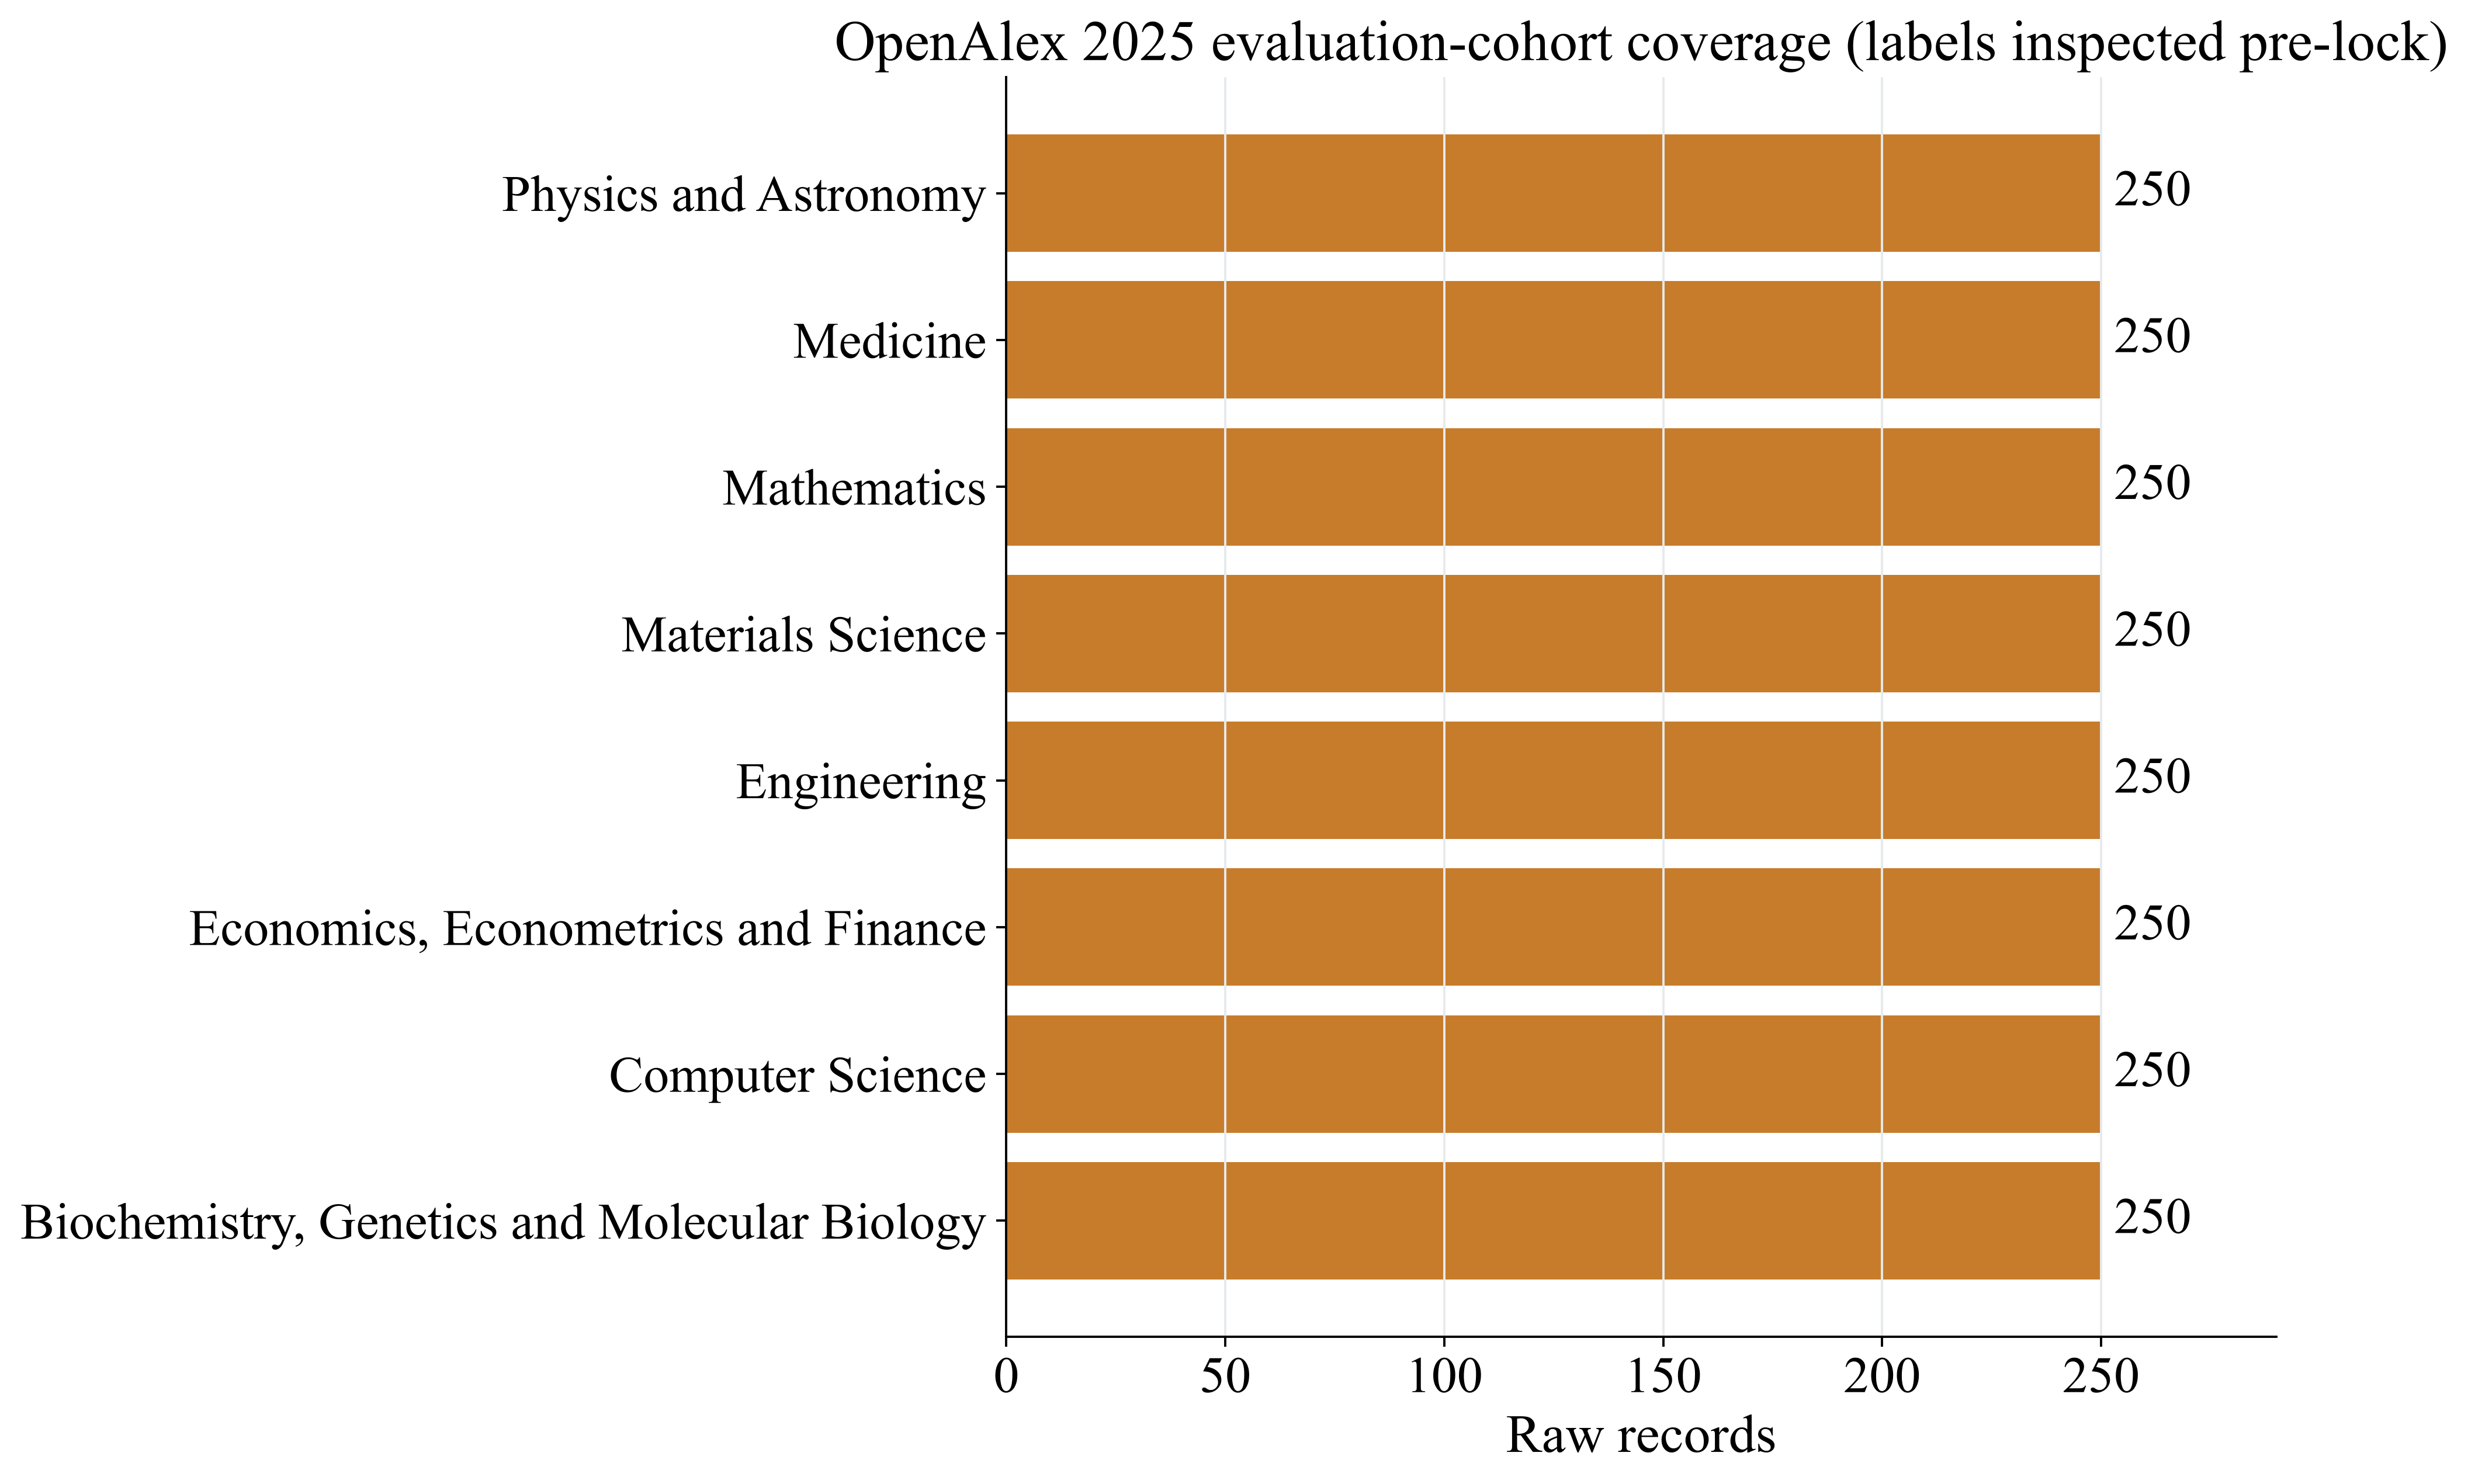

In [16]:
confirmatory_rows = []
for class_name, _, _ in CLASS_DESIGN:
    class_slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    class_records, seen_ids = [], set()
    for seed in CONFIRMATORY_SEEDS:
        raw_path = DIRS["openalex_raw"] / (f"confirmatory_2025__{class_slug}__seed_{seed}.json")
        for work in json.loads(raw_path.read_text(encoding="utf-8")).get("results", []):
            work_id = work.get("id", "")
            field_name = ((work.get("primary_topic") or {}).get("field") or {}).get(
                "display_name", ""
            )
            if work_id and work_id not in seen_ids and field_name == class_name:
                class_records.append(compact_openalex_record(work, class_name))
                seen_ids.add(work_id)
    confirmatory_rows.extend(sorted(class_records, key=lambda row: row["paper_id"])[:250])
openalex_confirmatory_df = pd.DataFrame(confirmatory_rows)
openalex_confirmatory_df.to_parquet(
    DIRS["processed"] / "openalex_confirmatory_2025_records.parquet", index=False
)
counts = (
    openalex_confirmatory_df.groupby("thematic_class", as_index=False).size().sort_values("size")
)
fig, ax = plt.subplots(figsize=(11.5, 8))
bars = ax.barh(counts["thematic_class"], counts["size"], color=PALETTE["orange"])
ax.set_title("OpenAlex 2025 evaluation-cohort coverage (labels inspected pre-lock)")
ax.set_xlabel("Raw records")
ax.set_ylabel("")
ax.grid(axis="x", color=PALETTE["light_gray"], linewidth=0.8)
ax.set_xlim(0, counts["size"].max() * 1.16)
for bar, value in zip(bars, counts["size"]):
    ax.text(
        value + 3, bar.get_y() + bar.get_height() / 2, f"{int(value)}", va="center", fontsize=18
    )
fig.subplots_adjust(left=0.36)
plt.show()

## Download a new arXiv-hosted external cohort through the official OpenAlex source filter

The arXiv Atom endpoint was unavailable during the protocol reset. The fallback uses OpenAlex source ID S4306400194 (arXiv, Cornell University), preserves raw official responses under dataset/raw/arxiv, and keeps the same OpenAlex primary-topic target ontology. This reduces taxonomy confounding while retaining a genuine repository/source shift.

In [17]:
external_manifest_rows = []
for class_name, field_id, _ in CLASS_DESIGN:
    class_slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    for seed in ARXIV_EXTERNAL_SEEDS:
        raw_path = DIRS["arxiv_raw"] / (
            f"openalex_indexed_arxiv_2024_2025__{class_slug}__seed_{seed}.json"
        )
        params = {
            "filter": (
                f"primary_location.source.id:{ARXIV_SOURCE_ID},"
                f"primary_topic.field.id:{field_id},has_abstract:true,language:en,"
                "from_publication_date:2024-01-01,to_publication_date:2025-12-31"
            ),
            "sample": 200,
            "seed": seed,
            "per-page": 200,
        }
        status, http_status = "reused", 200
        if not raw_path.exists():
            for attempt in range(5):
                response = session.get("https://api.openalex.org/works", params=params, timeout=90)
                http_status = response.status_code
                if response.ok:
                    raw_path.write_bytes(response.content)
                    status = "downloaded"
                    break
                time.sleep(min(2**attempt, 20))
            else:
                raise RuntimeError(f"OpenAlex-indexed arXiv request failed: {class_name}")
        payload = json.loads(raw_path.read_text(encoding="utf-8"))
        external_manifest_rows.append(
            {
                "source": "OpenAlex-indexed arXiv",
                "request_group": class_name,
                "cohort": "external_test_arxiv_hosted_2024_2025",
                "raw_file": str(raw_path.relative_to(PROJECT_ROOT)),
                "status": status,
                "http_status": http_status,
                "requested_records": 200,
                "response_records": len(payload.get("results", [])),
                "request_timestamp_utc": datetime.fromtimestamp(
                    raw_path.stat().st_mtime, tz=timezone.utc
                ).isoformat(),
                "parameters_json": json.dumps(params, sort_keys=True),
                "sha256": hashlib.sha256(raw_path.read_bytes()).hexdigest(),
                "license_or_terms_url": (
                    "https://docs.openalex.org; " "https://info.arxiv.org/help/api/tou.html"
                ),
            }
        )
external_download_df = pd.DataFrame(external_manifest_rows)
display(
    external_download_df.groupby(["cohort", "status"], as_index=False).agg(
        requests=("raw_file", "count"), records=("response_records", "sum")
    )
)
assert external_download_df["response_records"].gt(0).all()

,cohort,status,requests,records
0,external_test_arxiv_hosted_2024_2025,reused,16,3200


In [18]:
def arxiv_identifier(work):
    locations = [
        work.get("primary_location") or {},
        work.get("best_oa_location") or {},
        *(work.get("locations") or []),
    ]
    for location in locations:
        url = location.get("landing_page_url") or location.get("pdf_url") or ""
        match = re.search(r"arxiv\\.org/(?:abs|pdf)/([^?#/]+)", url)
        if match:
            return match.group(1).removesuffix(".pdf").split("v")[0]
    return ""


external_rows = []
for class_name, _, _ in CLASS_DESIGN:
    class_slug = re.sub(r"[^a-z0-9]+", "_", class_name.lower()).strip("_")
    candidates, seen_openalex = [], set()
    for seed in ARXIV_EXTERNAL_SEEDS:
        raw_path = DIRS["arxiv_raw"] / (
            f"openalex_indexed_arxiv_2024_2025__{class_slug}__seed_{seed}.json"
        )
        for work in json.loads(raw_path.read_text(encoding="utf-8")).get("results", []):
            work_id = work.get("id", "")
            field_name = ((work.get("primary_topic") or {}).get("field") or {}).get(
                "display_name", ""
            )
            if not work_id or work_id in seen_openalex or field_name != class_name:
                continue
            row = compact_openalex_record(work, class_name)
            arxiv_id = arxiv_identifier(work)
            stable_id = arxiv_id or work_id.rsplit("/", 1)[-1]
            row.update(
                {
                    "sample_id": f"arxiv:{stable_id}",
                    "source": "arxiv",
                    "paper_id": stable_id,
                    "source_name": "arXiv",
                    "source_type": "repository",
                    "work_type": "preprint",
                    "primary_category": "",
                    "categories_json": "[]",
                    "target_provenance": ("OpenAlex primary_topic.field for an arXiv-hosted work"),
                    "split_role": "external_test_only",
                }
            )
            candidates.append(row)
            seen_openalex.add(work_id)
    external_rows.extend(sorted(candidates, key=lambda row: row["sample_id"])[:ARXIV_PER_CLASS])
arxiv_external_confirmatory_df = pd.DataFrame(external_rows)
arxiv_external_confirmatory_df.to_parquet(
    DIRS["external"] / "arxiv_external_confirmatory_records.parquet", index=False
)
with pd.option_context("display.max_rows", None, "display.width", 180):
    display(
        arxiv_external_confirmatory_df.groupby(
            ["thematic_class", "publication_year"], as_index=False
        ).size()
    )

,thematic_class,publication_year,size
0,"Biochemistry, Genetics and Molecular Biology",2024,149
1,"Biochemistry, Genetics and Molecular Biology",2025,1
2,Computer Science,2024,150
3,"Economics, Econometrics and Finance",2024,150
4,Engineering,2024,150
5,Materials Science,2024,150
6,Mathematics,2024,150
7,Medicine,2024,150
8,Physics and Astronomy,2024,150


## Consolidated cohorts and target definition

In [19]:
openalex_df["cohort"] = "development_2018_2024"
arxiv_df["cohort"] = "source_shift_validation"
openalex_confirmatory_df["cohort"] = "confirmatory_test_2025"
arxiv_external_confirmatory_df["cohort"] = "external_test_arxiv_hosted_2024_2025"
all_audit = pd.concat(
    [
        openalex_df,
        arxiv_df,
        openalex_confirmatory_df,
        arxiv_external_confirmatory_df,
    ],
    ignore_index=True,
    sort=False,
)

cohort_summary = all_audit.groupby(["cohort", "source", "thematic_class"], as_index=False).agg(
    records=("paper_id", "size"),
    earliest_year=("publication_year", "min"),
    latest_year=("publication_year", "max"),
    abstract_coverage=("abstract", lambda s: s.fillna("").str.strip().ne("").mean()),
)
cohort_summary.to_csv(DIRS["tables"] / "source_class_year_language_summary.csv", index=False)
dataset_audit_summary = pd.DataFrame(
    [
        ("openalex_development_records", len(openalex_df)),
        ("arxiv_disclosed_validation_records", len(arxiv_df)),
        ("openalex_temporal_test_records", len(openalex_confirmatory_df)),
        ("arxiv_disjoint_external_records", len(arxiv_external_confirmatory_df)),
        ("semantic_scholar_enrichment_records", len(s2_records)),
        ("thematic_classes", all_audit["thematic_class"].nunique()),
    ],
    columns=["metric", "value"],
)
dataset_audit_summary.to_csv(DIRS["tables"] / "dataset_audit_summary.csv", index=False)
prospective_design.to_csv(DIRS["tables"] / "research_design_summary.csv", index=False)
display(dataset_audit_summary)

,metric,value
0,openalex_development_records,10000
1,arxiv_disclosed_validation_records,1193
2,openalex_temporal_test_records,2000
3,arxiv_disjoint_external_records,1200
4,semantic_scholar_enrichment_records,151
5,thematic_classes,8


In [20]:
crosswalk_scope = {
    "Computer Science": "broad CS wildcard",
    "Mathematics": "broad mathematics wildcard",
    "Physics and Astronomy": "astronomy subset only",
    "Engineering": "electrical-systems subset only",
    "Materials Science": "materials subset only",
    "Economics, Econometrics and Finance": "quantitative-finance subset only",
    "Biochemistry, Genetics and Molecular Biology": "quantitative-biology subset only",
    "Medicine": "medical-physics subset only",
}

target_definition_df = class_design_df[
    ["thematic_class", "openalex_field_id", "arxiv_query"]
].copy()
target_definition_df["legacy_arxiv_validation_crosswalk_scope"] = target_definition_df[
    "thematic_class"
].map(crosswalk_scope)
target_definition_df["primary_predictor_policy"] = (
    "title+abstract only; direct taxonomy excluded; keywords used as supervision"
)
target_definition_df.to_csv(DIRS["tables"] / "target_definition.csv", index=False)

with pd.option_context(
    "display.max_rows",
    None,
    "display.max_colwidth",
    None,
    "display.width",
    190,
):
    display(prospective_design)
display(target_definition_df)

,split,source_scope,time_scope,allowed_use,performance_metrics_seen_before_lock,label_diagnostics_seen_before_lock
0,train,OpenAlex articles,2018–2022,model fitting only,False,False
1,validation,OpenAlex articles + disclosed arXiv pilot,2023–2024 + 2026,model/configuration selection only,False,False
2,test,new OpenAlex articles,2025,single post-lock temporal evaluation,False,True
3,external_test,new OpenAlex-indexed arXiv-hosted works,2024–2025,single post-lock source+metadata+taxonomy stress evaluation,False,True
